# Gaussian Blur Sağlamlık Deneyi — Ahmet

**Tek değişken: sigma** (0 = filtresiz referans, 0.5, 1.5, 3.0; çekirdek 15×15). Çözünürlük, baş ROI, renk aralıkları ve karar eşikleri sabit.
Her K görüntüsü ve sigma için RGB/HSV maske alanı, baş örtüşmesi, sınıf ve TP/FP/FN ölçülür. Bulanık kopyalar yeni bağımsız görüntü sayılmaz.

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Deney öncesi tahmin

In [2]:
tahminler = pd.read_csv(KOK / "belgeler/tahminler.csv")
benim = tahminler[(tahminler.uye == "Ahmet")]
if benim.empty:
    print("UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'")
    print("Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.")
for _, t in benim.iterrows():
    print(f"[{t.kayit_tarihi}] {t.deney_kimligi}\n 1) {t.tahmin_1}\n 2) {t.tahmin_2}\n   ({t.durum})\n")

[2026-11-02] gaussian_blur_visual
 1) Sigma arttıkça renk sınırlarının yumuşamasını ve özellikle küçük baret ayrıntılarının kaybolmasını bekliyorum.
 2) Düşük ışıklı veya karmaşık arka planlı görüntülerde bu etkinin daha belirgin olabileceğini öngörüyorum.
   (üye tarafından yazıldı)

[2026-11-03] ahmet_gaussian_blur
 1) Gaussian Blur'un sigma değeri arttıkça görüntüdeki keskin renk geçişlerinin yumuşamasını ve özellikle küçük veya düşük ışıkta bulunan baretlerde RGB/HSV maske alanlarının değişmesini bekliyorum. Bulanıklaştırmanın bazı küçük maske parçalarını ortadan kaldırabileceğini, birbirine yakın bölgeleri birleştirebileceğini ve baş ROI örtüşmesindeki değişimlerin sınıflandırma kararını etkileyebileceğini öngörüyorum.
 2) K3'teki küçük baretlerin görüntüde sınırlı sayıda piksel kaplaması nedeniyle yüksek sigma değerlerinden daha fazla etkilenmesini bekliyorum. Özellikle σ=3.0 seviyesinde baret sınırlarının çevredeki renklerle karışması ve baş ROI içerisindeki maskeli piksel oranı

## 2. Sonuçlar (`python betikler/deneyleri_calistir.py` çıktısı)

In [3]:
b = pd.read_csv(KOK / "sonuclar/bulaniklik/bulaniklik_sonuclari.csv")
b[["kimlik", "sigma", "yontem", "maske_alani_yuzde", "bas_ortusmesi_yuzde", "kural_sinifi", "dogru_sinif", "dogru_mu", "tp", "fp", "fn"]]

,kimlik,sigma,yontem,maske_alani_yuzde,bas_ortusmesi_yuzde,kural_sinifi,dogru_sinif,dogru_mu,tp,fp,fn
0,K1,0.0,RGB,0.40,6.08,baret_yok,basta_baret,hayir,0,2,1
1,K1,0.0,HSV,0.81,12.69,baret_yok,basta_baret,hayir,1,0,0
2,K1,0.5,RGB,0.40,6.04,baret_yok,basta_baret,hayir,0,2,1
3,K1,0.5,HSV,0.81,12.70,baret_yok,basta_baret,hayir,1,0,0
4,K1,1.5,RGB,0.37,5.77,baret_yok,basta_baret,hayir,0,2,1
5,K1,1.5,HSV,0.81,12.67,baret_yok,basta_baret,hayir,1,0,0
6,K1,3.0,RGB,0.34,5.25,baret_yok,basta_baret,hayir,0,1,1
7,K1,3.0,HSV,0.80,12.48,baret_yok,basta_baret,hayir,1,0,0
8,K2,0.0,RGB,0.03,17.74,baret_yok,basta_baret,hayir,0,3,2
9,K2,0.0,HSV,0.03,17.88,baret_yok,basta_baret,hayir,1,2,1


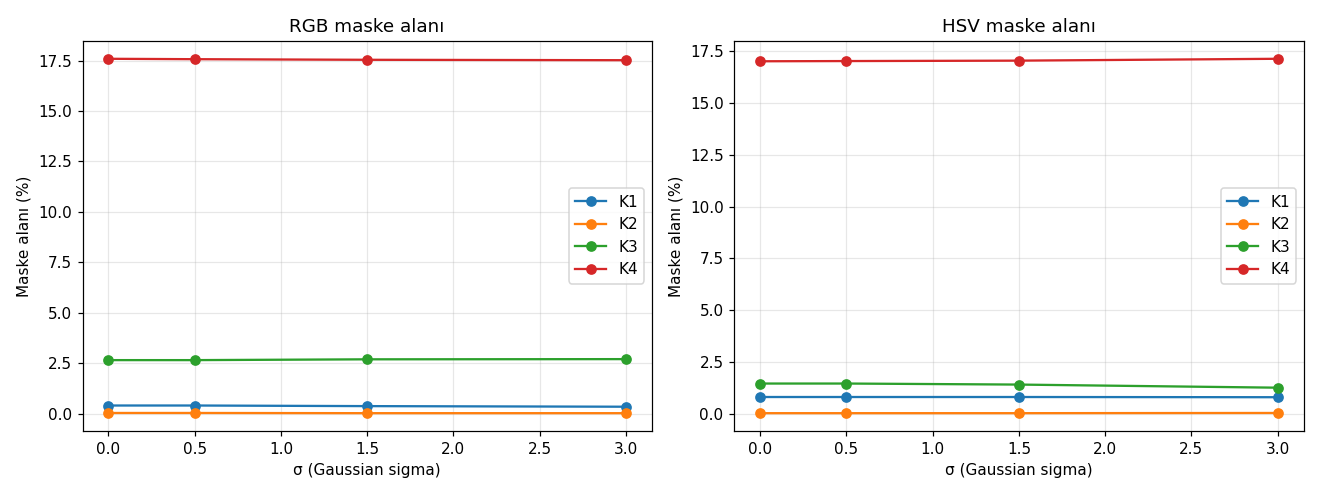

In [4]:
from IPython.display import Image, display
display(Image(filename=str(KOK / "sonuclar/bulaniklik/sigma_maske_alani.png")))

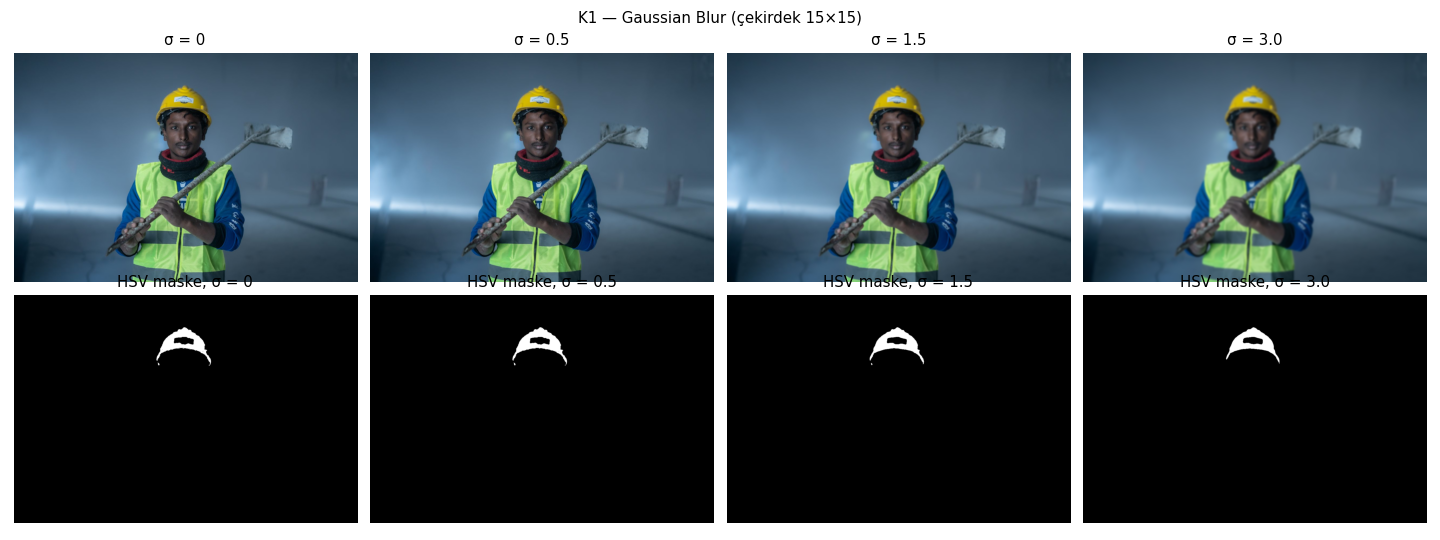

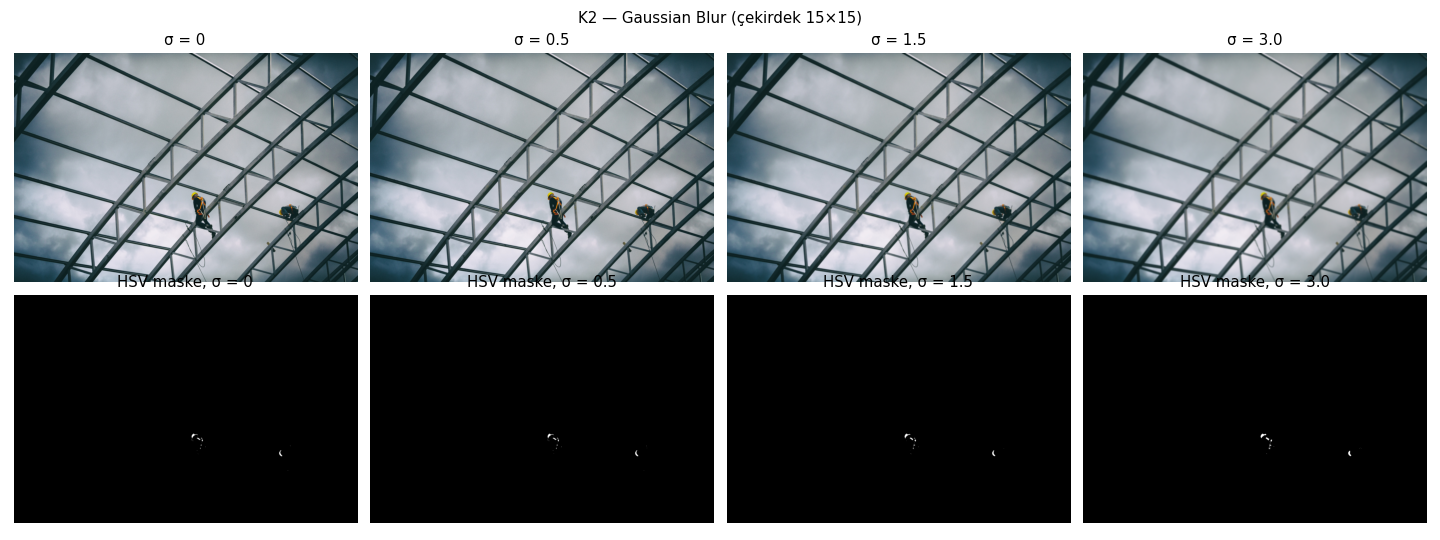

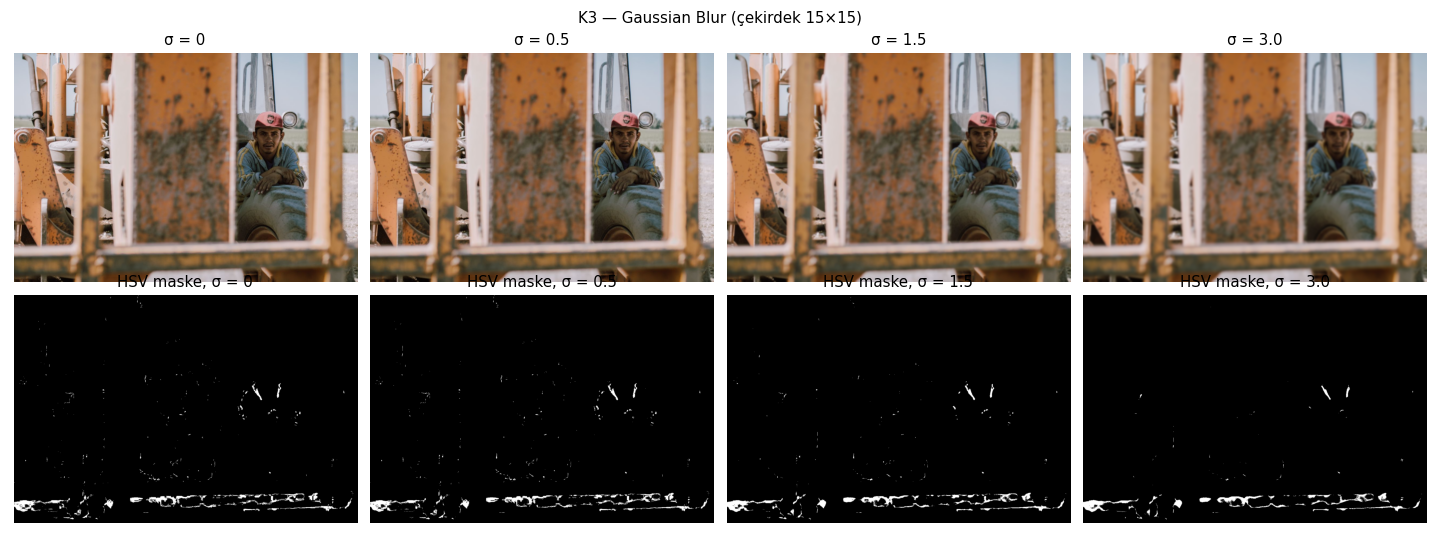

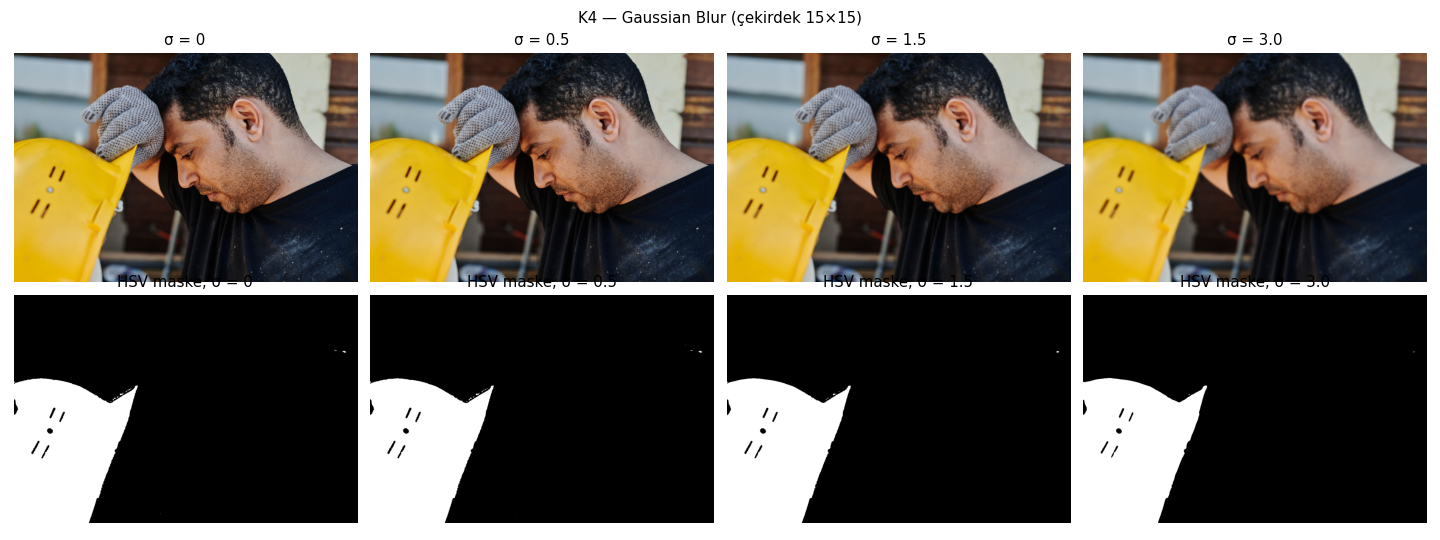

In [5]:
for k in ("K1", "K2", "K3", "K4"):
    display(Image(filename=str(KOK / f"sonuclar/bulaniklik/{k}_sigma.png"), width=900))

## 3. Sınıf değişimi

In [6]:
import json
print(json.loads((KOK / "sonuclar/ozet.json").read_text(encoding="utf-8"))["bulaniklik_sinif_degisimi"] or "Hiçbir görüntüde sınıf değişmedi.")

Hiçbir görüntüde sınıf değişmedi.


## 4. Yorum

### Deney Sonuçlarının Yorumu

Gaussian Blur deneyinde sigma değerini artırdığımda özellikle küçük baretlerde baş bölgesi örtüşmesinin azalacağını tahmin etmiştim. Sonuçlara baktığımda bu tahminimin kısmen gerçekleştiğini gördüm. Güncel veri setindeki küçük baret görüntüsü olan K2'de RGB baş örtüşmesi %17,74'ten %14,91'e düşerken HSV baş örtüşmesi %17,88'den %22,85'e yükseldi. Yani bulanıklaştırma iki renk yöntemini aynı şekilde etkilemedi.

Maske alanlarında ve baş örtüşme oranlarında değişiklik olmasına rağmen hiçbir görüntünün sınıflandırma sonucu değişmedi. Bunun nedeni, değişen ölçümlerin sınıflandırma kararını belirleyen eşiklerde farklı bir sonuca yol açmamasıydı. Özellikle K2'de toplam maske alanı %2,5 eşiğinin altında kaldığından, baş örtüşmesi yüksek olsa bile sistem `baret_yok` tahminini vermeye devam etti.

Bu deneyde dikkatimi çeken sınırlılık, küçük baretlerin görüntünün tamamına göre çok az alan kaplaması oldu. Sonraki çalışmada toplam görüntü alanı yerine baş bölgesi çevresindeki maske oranının hesaplanmasını deneyerek küçük baretlerin sınıflandırmasını iyileştirip iyileştirmediğini incelemek isterim.

**Ek not:** Eski veri setinde küçük baret K3 olarak adlandırılmıştı. Güncel veri setinde bu örnek K2'dir. Ön tahmin kayıtları değiştirilmemiştir.
